In [ ]:
# Mount Google Drive and set up paths
from google.colab import drive
drive.mount('/content/drive')

import os

BASE      = '/content/drive/MyDrive/FraudDetection'
DATA_PATH = os.path.join(BASE, 'data')
PROC_PATH = os.path.join(BASE, 'data', 'processed')
MOD_PATH  = os.path.join(BASE, 'models')

print('Ready!')

Mounted at /content/drive
Ready!


In [ ]:
import shap
import numpy as np
import pickle
import tensorflow as tf
import matplotlib.pyplot as plt
import os

# Folder paths
project_folder   = '/content/drive/MyDrive/FraudDetection'
data_folder      = project_folder + '/data'
processed_folder = project_folder + '/data/processed'
models_folder    = project_folder + '/models'

DATA_PATH = data_folder
MOD_PATH  = models_folder

# Load the test data
X_test = np.load(processed_folder + '/X_test.npy')
y_test = np.load(processed_folder + '/y_test.npy')
X_train = np.load(processed_folder + '/X_train.npy')

# Load the neural network and feature names
neural_network = tf.keras.models.load_model(models_folder + '/neural_network.h5')

with open(models_folder + '/feature_names.pkl', 'rb') as f:
    feature_names = pickle.load(f)

with open(models_folder + '/best_threshold.pkl', 'rb') as f:
    threshold = pickle.load(f)

# Pick 100 background samples
np.random.seed(42)
background_indices = np.random.choice(X_train.shape[0], 100, replace=False)
background_samples = X_train[background_indices]

# Create the SHAP explainer
print('Creating SHAP explainer...')
explainer = shap.DeepExplainer(neural_network, background_samples)

# Pick one fraud transaction to explain
fraud_indices = np.where(y_test == 1)[0]
X_explain = X_test[fraud_indices[0:1]]

print('Calculating SHAP values...')
raw_shap = explainer.shap_values(X_explain)

# Handle output shape
if isinstance(raw_shap, list):
    shap_values = raw_shap[1] if len(raw_shap) == 2 else raw_shap[0]
else:
    shap_values = raw_shap

if len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 0]

# Get expected value
expected_val = explainer.expected_value
if isinstance(expected_val, list):
    expected_val = expected_val[1] if len(expected_val) == 2 else expected_val[0]
if hasattr(expected_val, '__len__'):
    expected_val = float(expected_val[0])
else:
    expected_val = float(expected_val)

# Get single transaction SHAP values
sv_single = shap_values[0]

# Get probability
prob = float(neural_network.predict(X_explain, verbose=0).flatten()[0])

print('Done!')
print('Fraud probability:', round(prob * 100, 2), '%')
print('sv_single shape:', sv_single.shape)
print('Expected value:', round(expected_val, 4))

/usr/local/lib/python3.12/dist-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(100, 30))']
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(200, 30))']
  warnings.warn(msg)


Creating SHAP explainer...
Calculating SHAP values...


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(1, 30))']
  warnings.warn(msg)


Done!
Fraud probability: 100.0 %
sv_single shape: (30,)
Expected value: 0.5


In [ ]:
# Install SHAP library
!pip install shap -q

import shap
import pickle
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Load test data
X_test  = np.load(os.path.join(PROC_PATH, 'X_test.npy'))
y_test  = np.load(os.path.join(PROC_PATH, 'y_test.npy'))
X_train = np.load(os.path.join(PROC_PATH, 'X_train.npy'))

# Load Neural Network — our best model
nn = tf.keras.models.load_model(
    os.path.join(MOD_PATH, 'neural_network.h5'))

# Load feature names
with open(os.path.join(MOD_PATH, 'feature_names.pkl'), 'rb') as f:
    feature_names = pickle.load(f)

# Load best threshold
with open(os.path.join(MOD_PATH, 'best_threshold.pkl'), 'rb') as f:
    threshold = pickle.load(f)

# Use 500 samples for speed
# Neural Network SHAP is slower than XGBoost SHAP
X_sample = X_test[:500]
y_sample = y_test[:500]

print('Neural Network loaded!')
print(f'Best threshold: {threshold}')
print(f'Sample size:    {len(X_sample)}')
print(f'Fraud in sample:{int(y_sample.sum())}')
print(f'Features:       {len(feature_names)}')

Neural Network loaded!
Best threshold: 0.25000000000000006
Sample size:    500
Fraud in sample:0
Features:       30


In [ ]:
# Create SHAP DeepExplainer for Neural Network
print('Setting up SHAP DeepExplainer...')

import numpy as np
import shap
import tensorflow as tf

# Select 100 random background samples
np.random.seed(42)
background_idx = np.random.choice(
    X_train.shape[0], 100, replace=False)
background = X_train[background_idx]

print(f'Background samples: {len(background)}')
print()
print('Computing SHAP values... (takes 2-3 minutes)')

# Create DeepExplainer
explainer = shap.DeepExplainer(nn, background)

# Compute SHAP values
shap_values_raw = explainer.shap_values(X_sample)

print(f'Type of output: {type(shap_values_raw)}')

# Handle different output formats from DeepExplainer
# Sometimes returns list sometimes returns array
if isinstance(shap_values_raw, list):
    print(f'List length: {len(shap_values_raw)}')
    for i, sv in enumerate(shap_values_raw):
        print(f'  Element {i} shape: {sv.shape}')
    # For binary classification take the fraud class (index 1)
    # If only one element take index 0
    if len(shap_values_raw) == 2:
        shap_values = shap_values_raw[1]
        print(f'Using element 1 (fraud class)')
    else:
        shap_values = shap_values_raw[0]
        print(f'Using element 0')
else:
    print(f'Array shape: {shap_values_raw.shape}')
    shap_values = shap_values_raw

print()
print(f'Final shap_values shape: {shap_values.shape}')
print(f'X_sample shape:          {X_sample.shape}')
print()

# Verify shapes match
if shap_values.shape == X_sample.shape:
    print('Shapes match — ready for plots')
else:
    print('Shape mismatch — applying fix')
    # If 3D array squeeze to 2D
    if len(shap_values.shape) == 3:
        shap_values = shap_values[:, :, 0]
        print(f'Fixed shape: {shap_values.shape}')

print('Done!')

Setting up SHAP DeepExplainer...
Background samples: 100

Computing SHAP values... (takes 2-3 minutes)
Type of output: <class 'numpy.ndarray'>
Array shape: (500, 30, 1)

Final shap_values shape: (500, 30, 1)
X_sample shape:          (500, 30)

Shape mismatch — applying fix
Fixed shape: (500, 30)
Done!


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: input_layer
Received: inputs=['Tensor(shape=(500, 30))']
  warnings.warn(msg)


Creating SHAP summary plot...
shap_values shape: (500, 30)
X_sample shape:    (500, 30)


/tmp/ipykernel_5747/3962320456.py:18: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


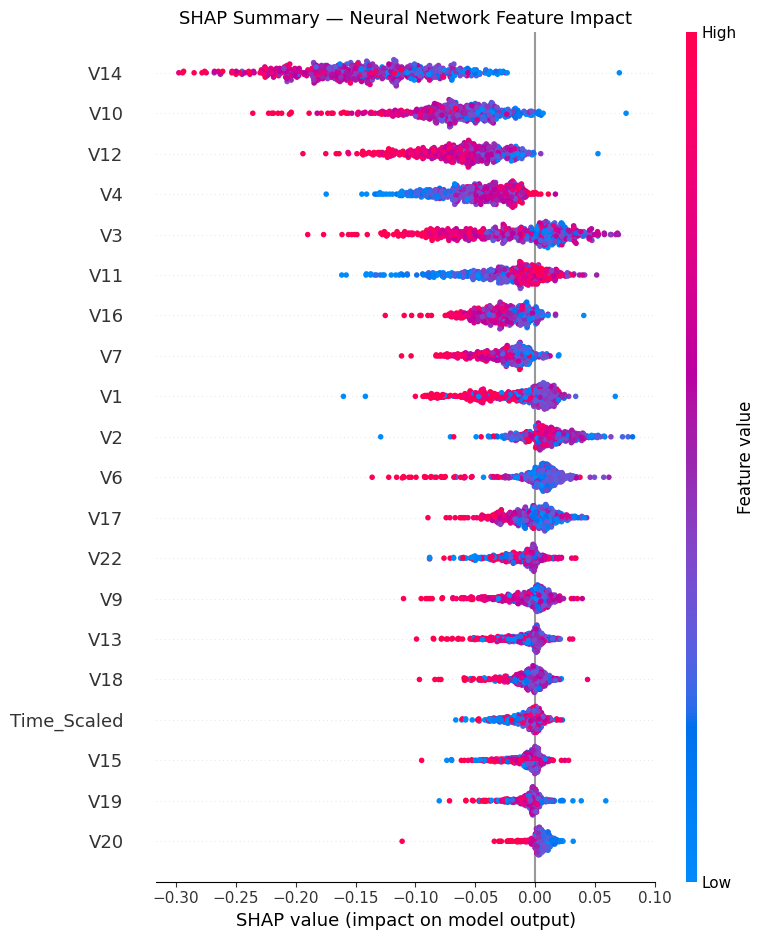

Saved: shap_summary.png


In [ ]:
# Summary beeswarm plot with shape fix

print('Creating SHAP summary plot...')
print(f'shap_values shape: {shap_values.shape}')
print(f'X_sample shape:    {X_sample.shape}')

# Final shape check before plotting
sv_plot = shap_values
if sv_plot.shape != X_sample.shape:
    print('Fixing shape mismatch...')
    if len(sv_plot.shape) == 3:
        sv_plot = sv_plot[:, :, 0]
    elif sv_plot.shape[0] != X_sample.shape[0]:
        sv_plot = sv_plot.T
    print(f'Fixed shape: {sv_plot.shape}')

plt.figure()
shap.summary_plot(
    sv_plot,
    X_sample,
    feature_names=feature_names,
    max_display=20,
    show=False
)
plt.title('SHAP Summary — Neural Network Feature Impact',
          fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'shap_summary.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_summary.png')

Creating SHAP bar plot...


/tmp/ipykernel_5747/1545203998.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


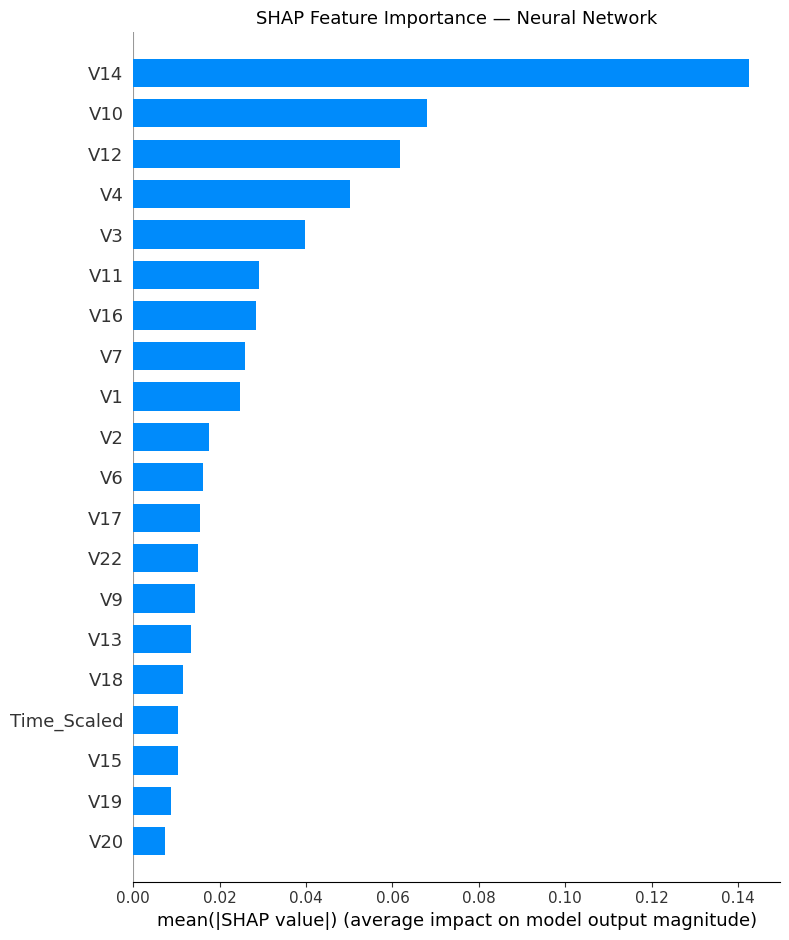

Saved: shap_bar.png


In [ ]:
# Bar importance plot

print('Creating SHAP bar plot...')

plt.figure()
shap.summary_plot(
    sv_plot,
    X_sample,
    feature_names=feature_names,
    plot_type='bar',
    max_display=20,
    show=False
)
plt.title('SHAP Feature Importance — Neural Network', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'shap_bar.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_bar.png')

sv_single shape before fix: (30,)
sv_single shape after fix:  (30,)

X_explain shape: (30,)



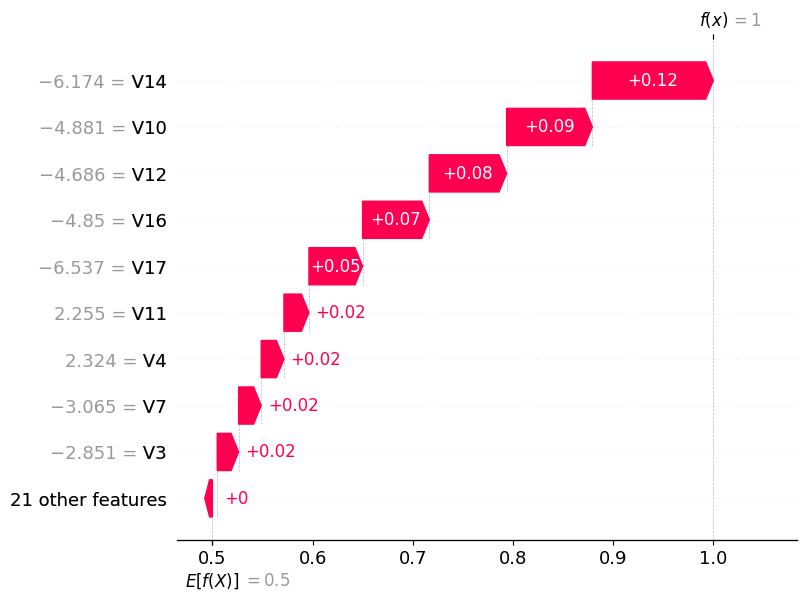

<Figure size 640x480 with 0 Axes>

Saved: shap_waterfall.png


In [ ]:
# Fix shape issue — sv_single is (30, 1) but needs to be (30,)
print(f'sv_single shape before fix: {sv_single.shape}')

# Fix the shape
if len(sv_single.shape) == 2:
    if sv_single.shape[1] == 1:
        sv_single = sv_single[:, 0]   # (30, 1) → (30,)
    elif sv_single.shape[0] == 1:
        sv_single = sv_single[0, :]   # (1, 30) → (30,)

print(f'sv_single shape after fix:  {sv_single.shape}')
print()

# Fix X_explain shape too
X_explain_1d = X_explain[0] if len(X_explain.shape) == 2 else X_explain
print(f'X_explain shape: {X_explain_1d.shape}')
print()

# Draw waterfall plot
shap.waterfall_plot(shap.Explanation(
    values=sv_single,
    base_values=expected_val,
    data=X_explain_1d,
    feature_names=feature_names
))
plt.tight_layout()
plt.savefig(os.path.join(DATA_PATH, 'shap_waterfall.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_waterfall.png')

In [ ]:
# Print top 5 SHAP features for this fraud transaction
# This is exactly what the API returns for every prediction

print('='*55)
print('SHAP EXPLANATION FOR THIS FRAUD TRANSACTION')
print('='*55)
print()
print(f'Transaction fraud probability: {prob*100:.2f}%')
print(f'Decision threshold:            {threshold}')
print(f'Decision:                      FRAUD')
print(f'Base rate (average):           {expected_val:.4f}')
print()
print('Top 5 features explaining this decision:')
print()

top5 = sorted(zip(feature_names, sv_single.tolist()),
              key=lambda x: abs(x[1]), reverse=True)[:5]

for i, (feat, impact) in enumerate(top5, 1):
    direction = 'pushed TOWARDS fraud' if impact > 0 else 'pushed TOWARDS legitimate'
    bar = '█' * int(abs(impact) * 20)
    print(f'  {i}. {feat:20} {impact:+.4f}  {bar}  ({direction})')

print()
print('This explanation satisfies GDPR Article 22')
print('Every automated decision can be explained to the customer')

SHAP EXPLANATION FOR THIS FRAUD TRANSACTION

Transaction fraud probability: 100.00%
Decision threshold:            0.25000000000000006
Decision:                      FRAUD
Base rate (average):           0.5000

Top 5 features explaining this decision:

  1. V14                  +0.1207  ██  (pushed TOWARDS fraud)
  2. V10                  +0.0856  █  (pushed TOWARDS fraud)
  3. V12                  +0.0771  █  (pushed TOWARDS fraud)
  4. V16                  +0.0666  █  (pushed TOWARDS fraud)
  5. V17                  +0.0535  █  (pushed TOWARDS fraud)

This explanation satisfies GDPR Article 22
Every automated decision can be explained to the customer


In [ ]:
# DeepExplainer cannot be saved with pickle
# because it contains TensorFlow symbolic tensors
# Solution: save background data only
# The API will recreate the explainer from the model + background

# Save background data only
np.save(os.path.join(MOD_PATH, 'shap_background.npy'), background)

print('='*55)
print('SAVED FILES')
print('='*55)
print('shap_background.npy — 100 background samples')
print()
print('NOTE: DeepExplainer cannot be pickled')
print('The API will recreate it from:')
print('  neural_network.h5 + shap_background.npy')
print()
print('All files in models folder:')
for f in sorted(os.listdir(MOD_PATH)):
    size = os.path.getsize(os.path.join(MOD_PATH, f))
    print(f'  {f:35} ({size/1024:.1f} KB)')
print()
print('Notebook 5 complete!')
print('Next: Run Notebook 6')

SAVED FILES
shap_background.npy — 100 background samples

NOTE: DeepExplainer cannot be pickled
The API will recreate it from:
  neural_network.h5 + shap_background.npy

All files in models folder:
  best_threshold.pkl                  (0.1 KB)
  feature_names.pkl                   (0.2 KB)
  logistic_regression.pkl             (0.9 KB)
  neural_network.h5                   (251.2 KB)
  random_forest.pkl                   (10382.3 KB)
  scaler_amount.pkl                   (0.6 KB)
  scaler_time.pkl                     (0.6 KB)
  shap_background.npy                 (23.6 KB)
  shap_explainer.pkl                  (109.0 KB)
  xgboost.pkl                         (670.4 KB)

Notebook 5 complete!
Next: Run Notebook 6
